# CÂU 1: NHẬP DỮ LIỆU ĐẦU VÀO

In [1]:
print("NguyenDucTinh - 6451071077")

# Import thư viện
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

# Đọc dữ liệu
train_data = pd.read_csv('adult.data.csv')
test_data = pd.read_csv('adult.test.csv')

print("Number of training data:", len(train_data))
print("Number of test data:", len(test_data))


NguyenDucTinh - 6451071077
Number of training data: 32561
Number of test data: 16281


# CÂU 2: TIỀN XỬ LÝ DỮ LIỆU

In [2]:

print("NguyenDucTinh - 6451071077")

# Thay thế hoặc lọc bỏ các dòng có dấu '?'
train_data = train_data[(train_data != '?').all(axis=1)]
test_data = test_data[(test_data != '?').all(axis=1)]

# Xóa cột 'fnlwgt' trong tập huấn luyện
if 'fnlwgt' in train_data.columns:
    train_data = train_data.drop('fnlwgt', axis=1)

# Nối dữ liệu huấn luyện và kiểm thử lại với nhau
data = pd.concat([train_data, test_data], ignore_index=True)


# Xóa cột fnlwgt
train_data = train_data.drop(
    columns=['fnlwgt'],
    errors='ignore'
)

test_data = test_data.drop(
    columns=['fnlwgt'],
    errors='ignore'
)

# Gộp dữ liệu huấn luyện và kiểm thử
data = pd.concat(
    [train_data, test_data],
    ignore_index=True
)


# In thông tin dữ liệu sau khi nối
data.info()

NguyenDucTinh - 6451071077
<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       48842 non-null  str  
 2   education       48842 non-null  str  
 3   education-num   48842 non-null  int64
 4   marital-status  48842 non-null  str  
 5   occupation      48842 non-null  str  
 6   relationship    48842 non-null  str  
 7   race            48842 non-null  str  
 8   sex             48842 non-null  str  
 9   capital-gain    48842 non-null  int64
 10  capital-loss    48842 non-null  int64
 11  hours-per-week  48842 non-null  int64
 12  native-country  48842 non-null  str  
 13  income          48842 non-null  str  
dtypes: int64(5), str(9)
memory usage: 5.2 MB


# CÂU 3: KHẢO SÁT ĐỘ TƯƠNG ĐỒNG PEARSON

NguyenDucTinh - 6451071077


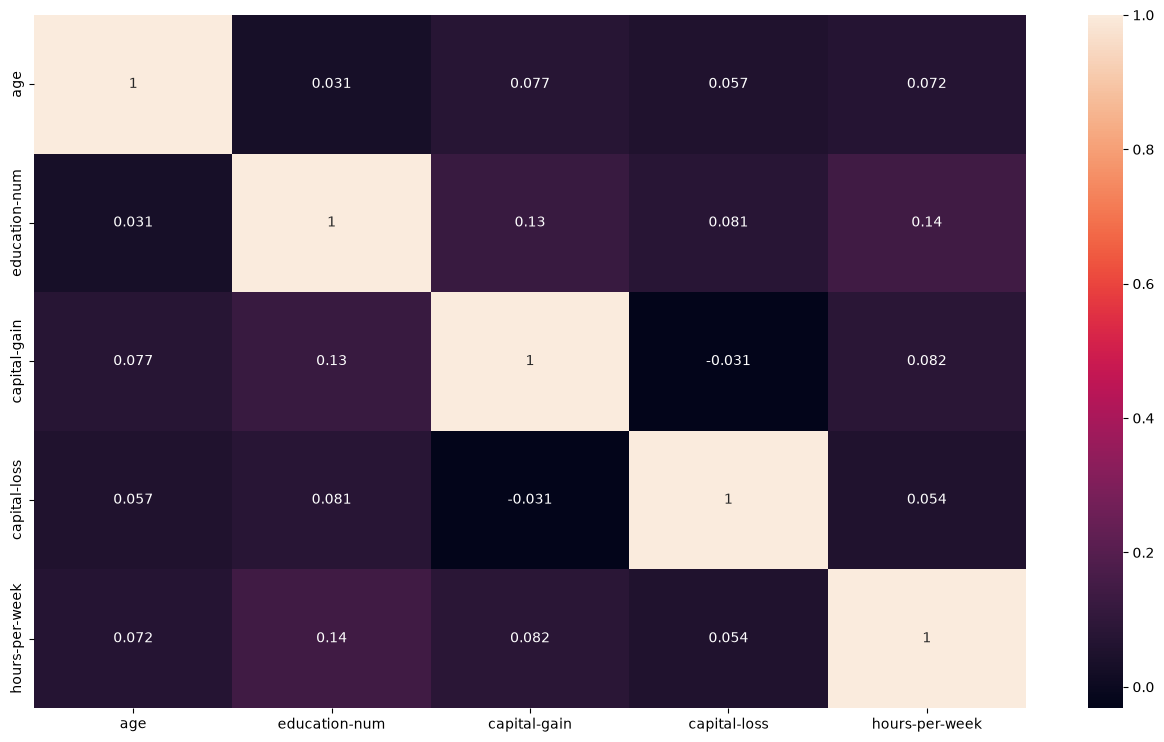

In [3]:
print("NguyenDucTinh - 6451071077")

plt.figure(figsize=(16, 9))
sns.heatmap(data.corr(method='pearson', numeric_only=True), annot=True)
plt.show()

# CÂU 4: TÁCH FEATURES VÀ LABELS

In [4]:
print("NguyenDucTinh - 6451071077")

features = data.drop('income', axis=1)
labels = data['income']

NguyenDucTinh - 6451071077


# CÂU 5: CHUYỂN ĐỔI ONE-HOT VECTOR

In [5]:
print("NguyenDucTinh - 6451071077")

# Xác định các cột không phải kiểu số
non_numeric_cols = features.select_dtypes(exclude=['int64' ]).columns
print(non_numeric_cols)

# Chuyển đổi về dạng one-hot vector
features_onehot = pd.get_dummies(
    features, 
    columns=features.select_dtypes(exclude=['int64']).columns, 
    dtype=int
)
features_onehot

NguyenDucTinh - 6451071077
Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country'],
      dtype='str')


,age,education-num,capital-gain,capital-loss,hours-per-week,workclass_ ?,workclass_ Federal-gov,workclass_ Local-gov,workclass_ Never-worked,workclass_ Private,...,native-country_ Portugal,native-country_ Puerto-Rico,native-country_ Scotland,native-country_ South,native-country_ Taiwan,native-country_ Thailand,native-country_ Trinadad&Tobago,native-country_ United-States,native-country_ Vietnam,native-country_ Yugoslavia
0,39,13,2174,0,40,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,50,13,0,0,13,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,38,9,0,0,40,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
3,53,7,0,0,40,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
4,28,13,0,0,40,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,39,13,0,0,36,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
48838,64,9,0,0,40,1,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
48839,38,13,0,0,50,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
48840,44,13,5455,0,40,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0


# CÂU 6: TÁCH DỮ LIỆU HUẤN LUYỆN VÀ KIỂM THỬ

In [6]:
print("NguyenDucTinh - 6451071077")

X_train = features_onehot[:30162]
X_test = features_onehot[30162:]
y_train = labels[:30162]
y_test = labels[30162:]

NguyenDucTinh - 6451071077


# CÂU 7: XÂY DỰNG CÂY QUYẾT ĐỊNH ID3

NguyenDucTinh - 6451071077
Accuracy (ID3): 0.8220556745182013
Report:
               precision    recall  f1-score   support

       <=50K       0.88      0.89      0.88     14230
        >50K       0.63      0.60      0.62      4450

    accuracy                           0.82     18680
   macro avg       0.76      0.75      0.75     18680
weighted avg       0.82      0.82      0.82     18680



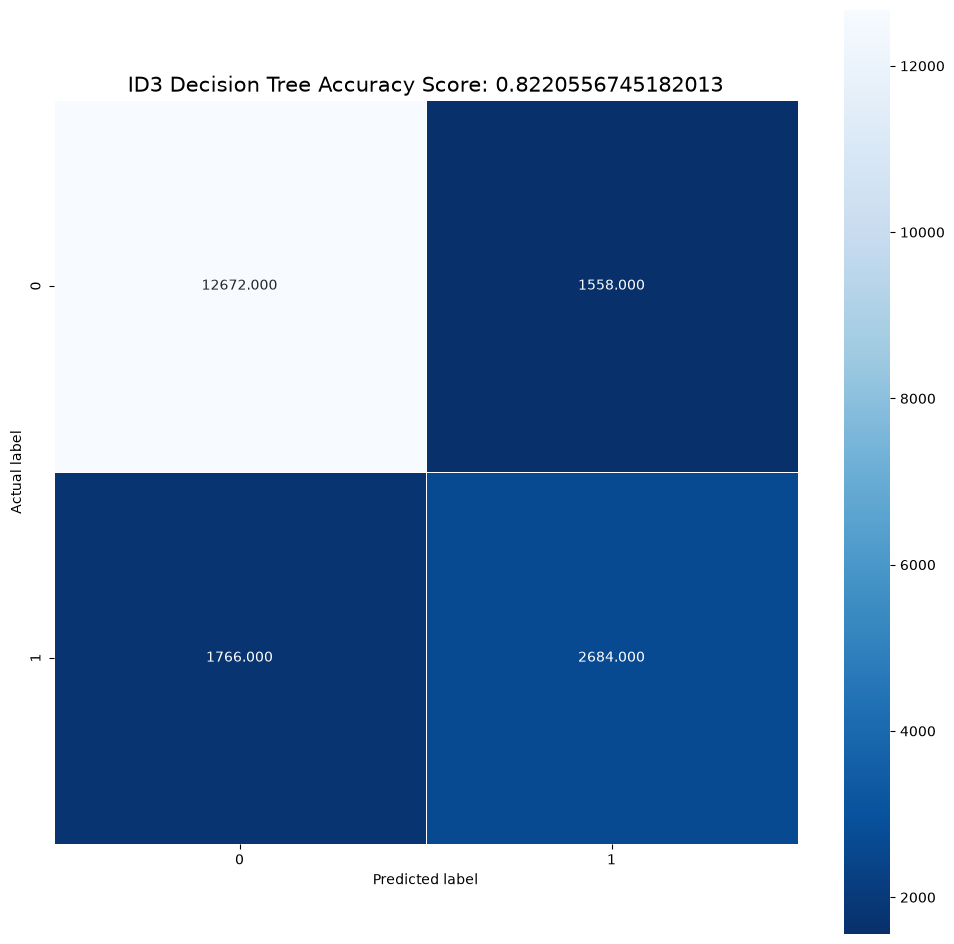

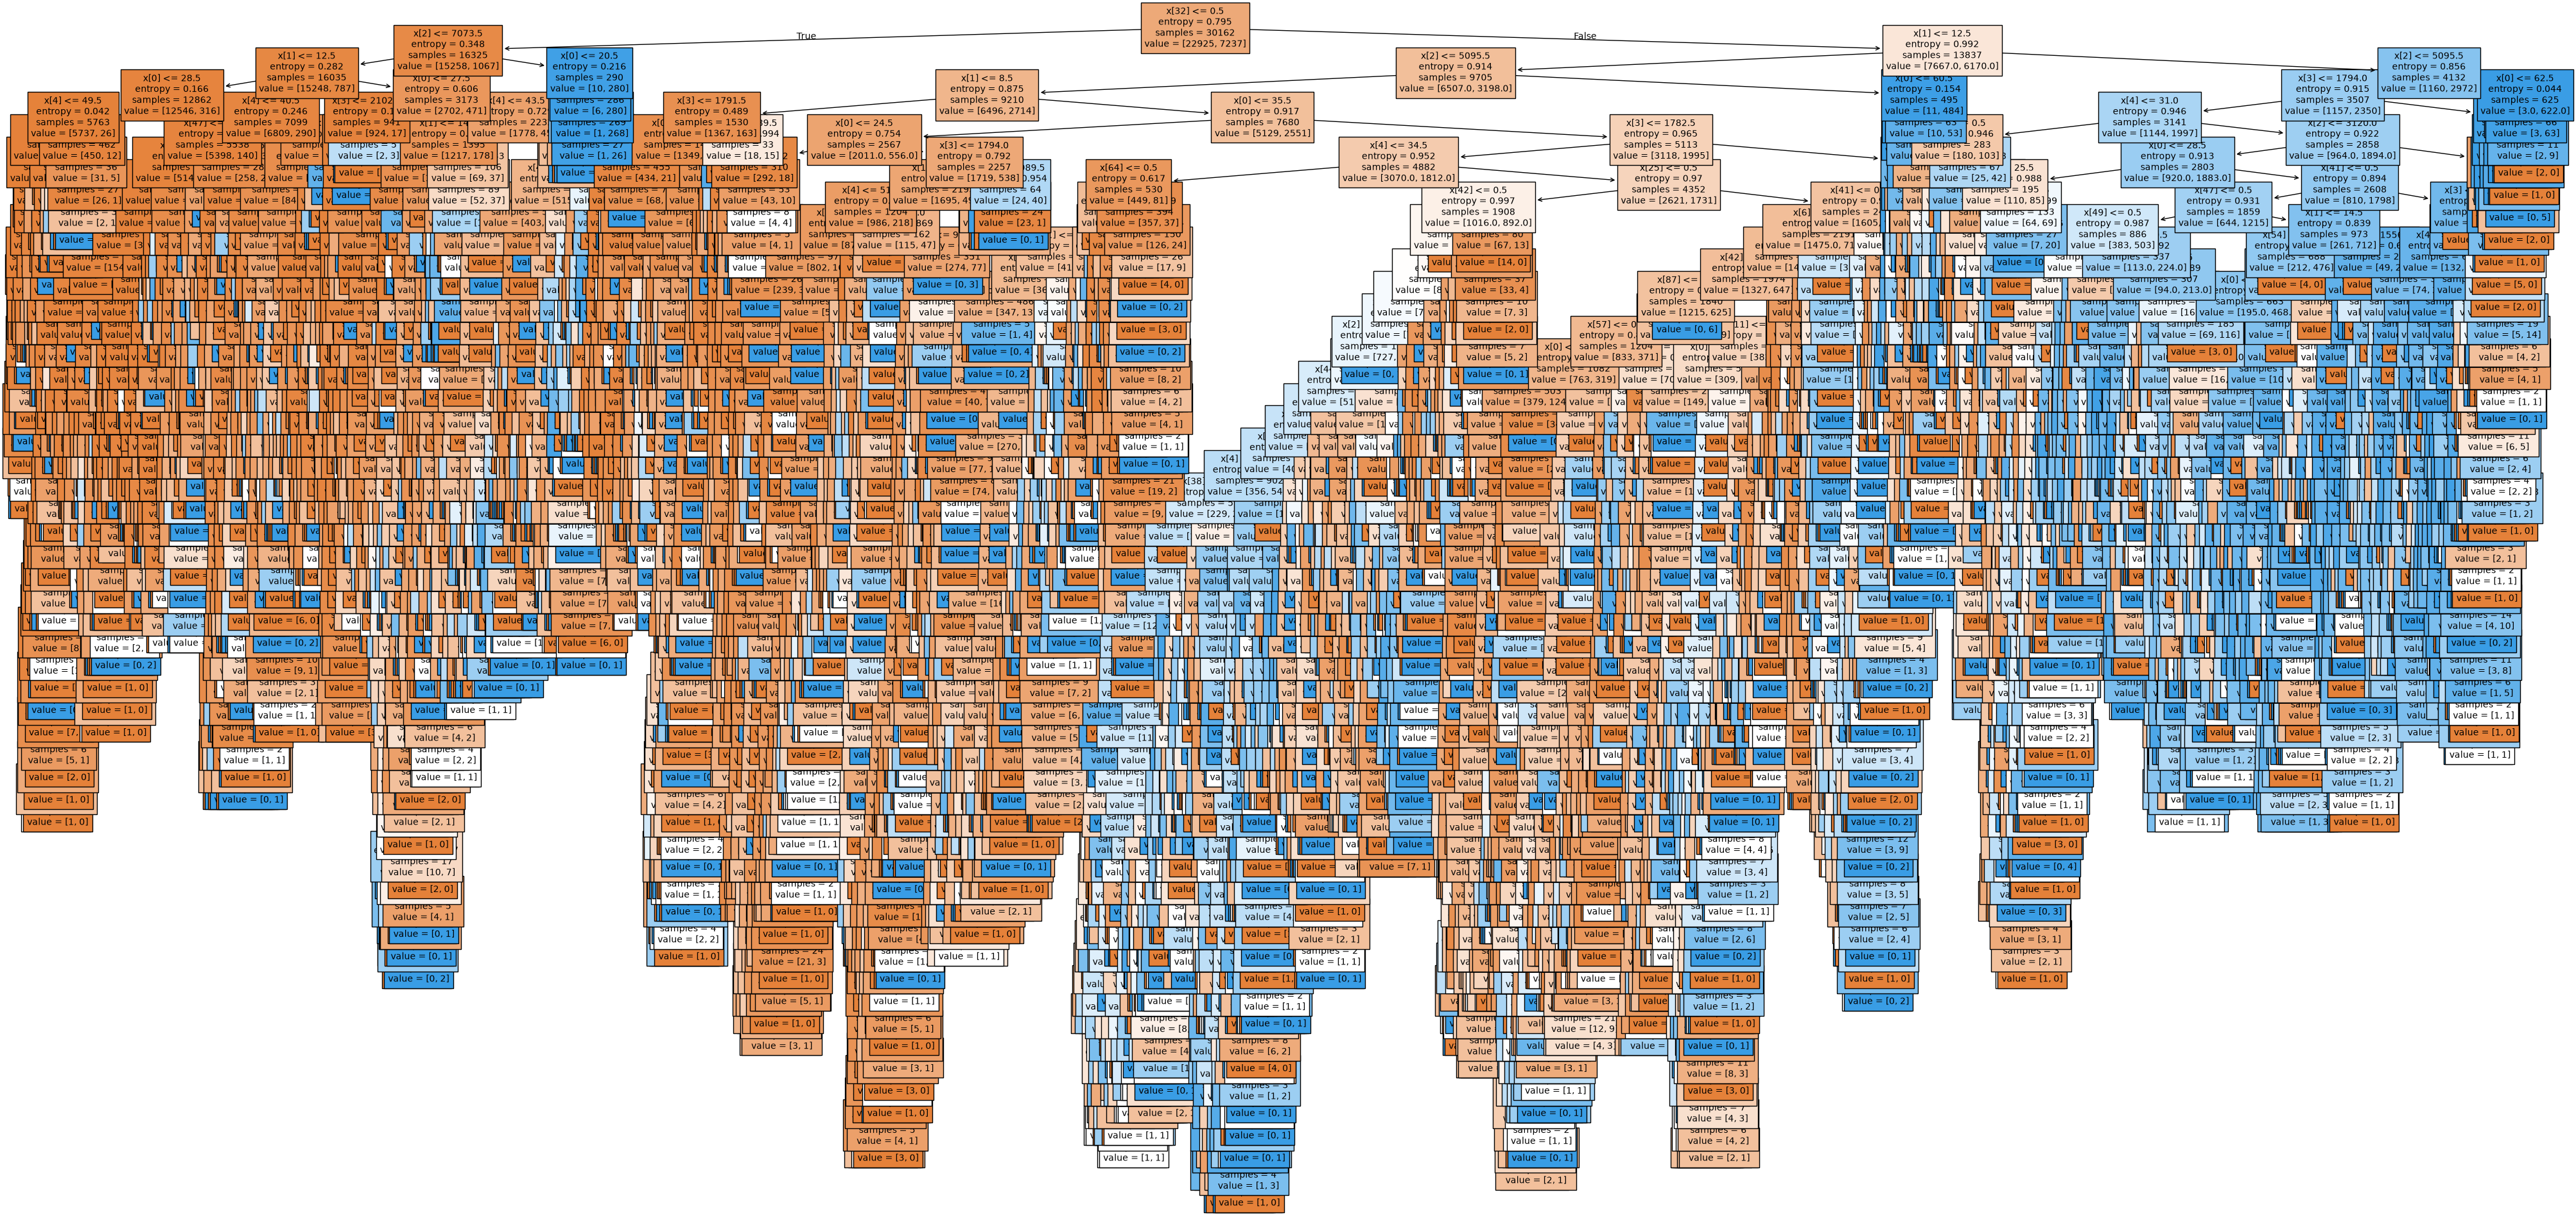

In [7]:
print("NguyenDucTinh - 6451071077")

# Huấn luyện mô hình ID3
clf_id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
clf_id3.fit(X_train, y_train)

# Dự đoán trên tập kiểm thử
tree_pred = clf_id3.predict(X_test)
tree_score = metrics.accuracy_score(y_test, tree_pred)

print("Accuracy (ID3):", tree_score)
print("Report:\n", metrics.classification_report(y_test, tree_pred))

# Tính toán và vẽ ma trận nhầm lẫn (Confusion Matrix)
tree_cm = metrics.confusion_matrix(y_test, tree_pred)
plt.figure(figsize=(12, 12))
sns.heatmap(tree_cm, annot=True, fmt=".3f", linewidths=.5, square=True, cmap='Blues_r')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'ID3 Decision Tree Accuracy Score: {tree_score}', size=15)
plt.show()

# Biểu diễn và lưu cấu trúc cây quyết định
fig, ax = plt.subplots(figsize=(50, 24))
tree.plot_tree(clf_id3, filled=True, fontsize=10)
plt.savefig('decision_tree_id3.png', dpi=100)
plt.show()

# CÂU 8: XÂY DỰNG CÂY QUYẾT ĐỊNH CART

NguyenDucTinh - 6451071077
Accuracy (CART): 0.8167558886509636
Report:
               precision    recall  f1-score   support

       <=50K       0.88      0.88      0.88     14230
        >50K       0.62      0.60      0.61      4450

    accuracy                           0.82     18680
   macro avg       0.75      0.74      0.75     18680
weighted avg       0.81      0.82      0.82     18680



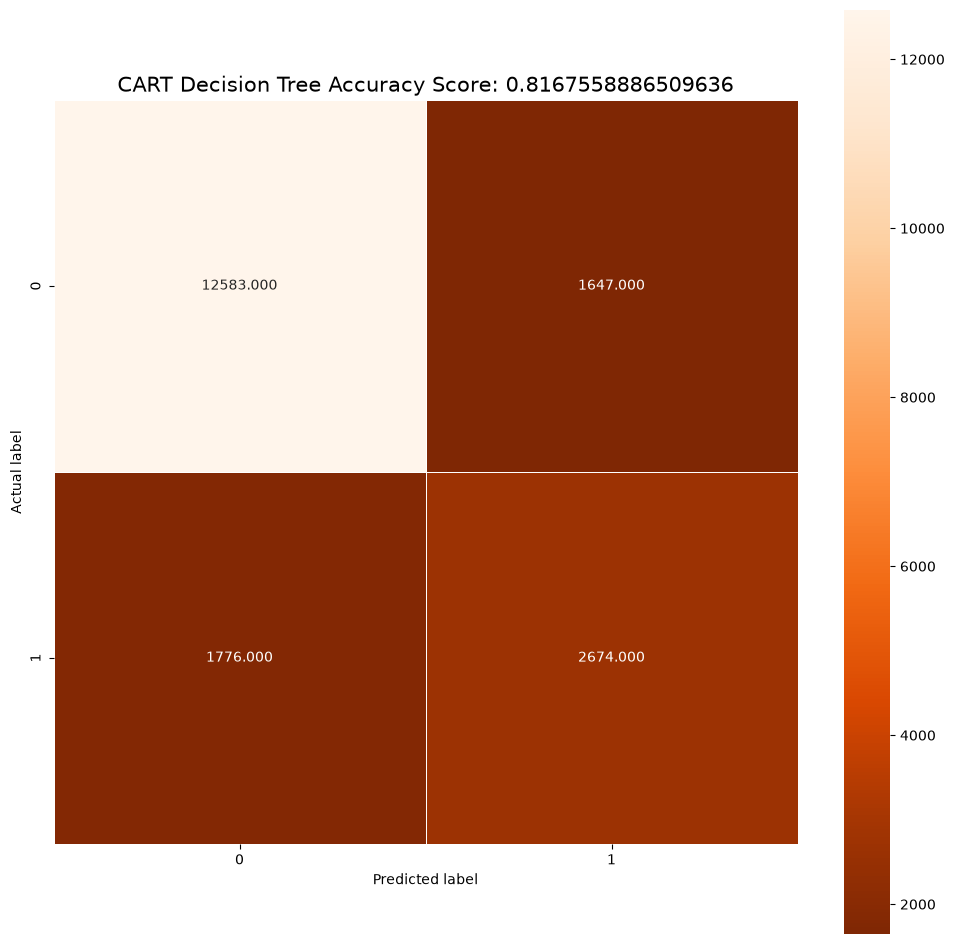

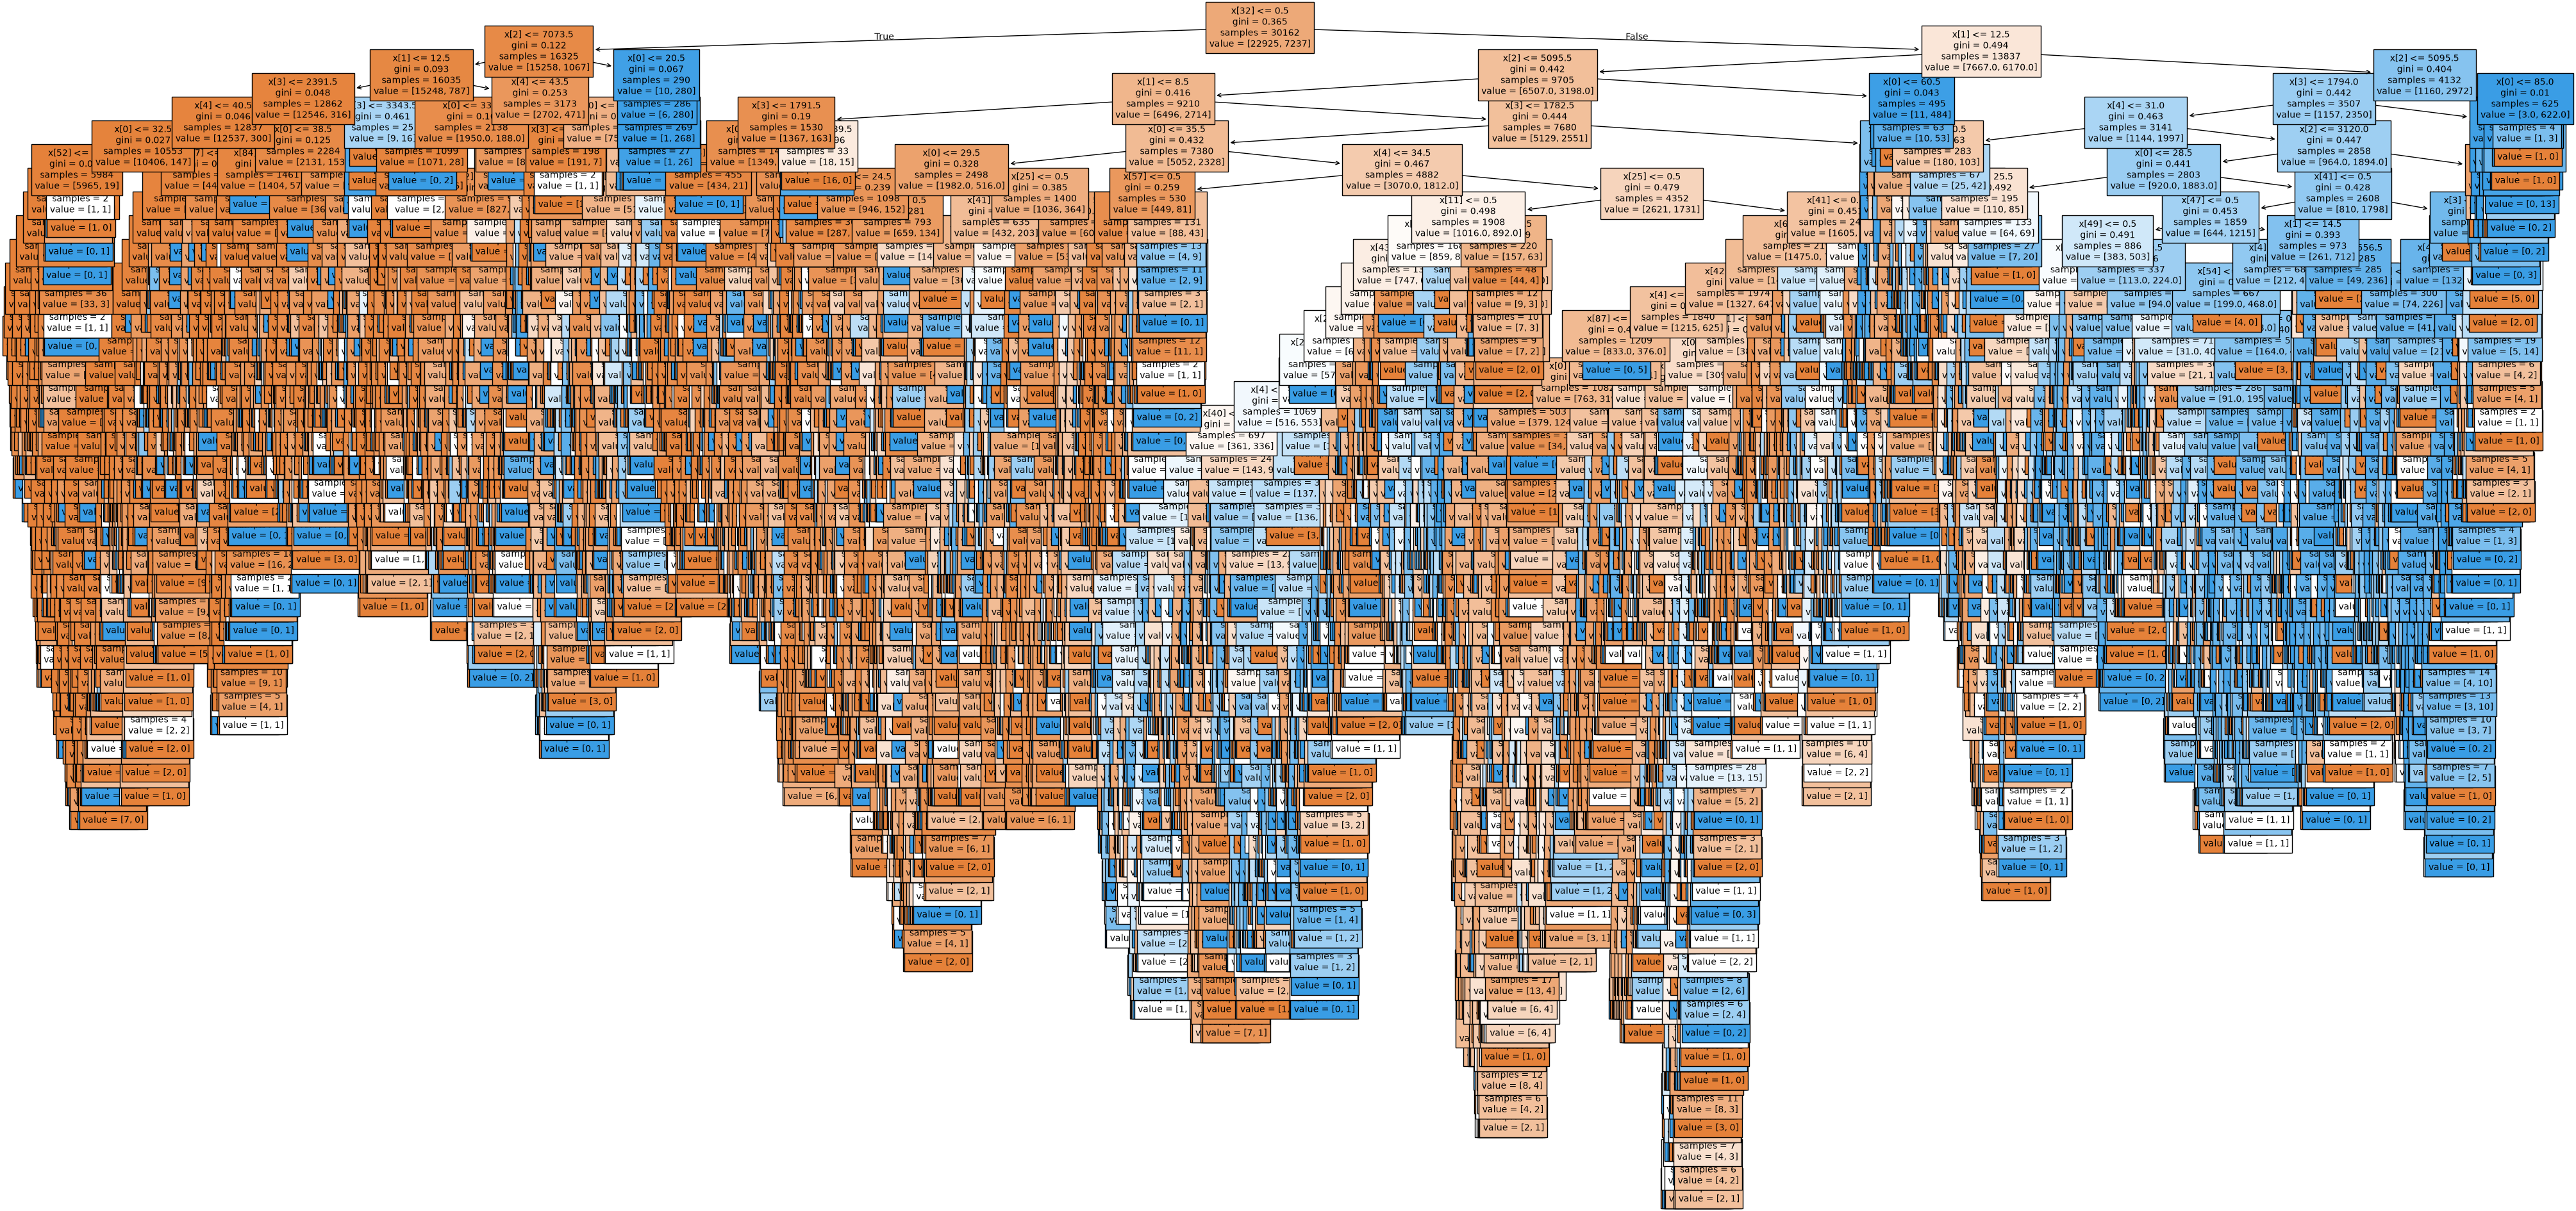

In [8]:
print("NguyenDucTinh - 6451071077")

# Huấn luyện mô hình CART
clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
clf_cart.fit(X_train, y_train)

# Dự đoán và đánh giá
cart_pred = clf_cart.predict(X_test)
cart_score = metrics.accuracy_score(y_test, cart_pred)

print("Accuracy (CART):", cart_score)
print("Report:\n", metrics.classification_report(y_test, cart_pred))

# Ma trận nhầm lẫn cho CART
cart_cm = metrics.confusion_matrix(y_test, cart_pred)
plt.figure(figsize=(12, 12))
sns.heatmap(cart_cm, annot=True, fmt=".3f", linewidths=.5, square=True, cmap='Oranges_r')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'CART Decision Tree Accuracy Score: {cart_score}', size=15)
plt.show()

# Biểu diễn và lưu cấu trúc cây quyết định CART
fig, ax = plt.subplots(figsize=(50, 24))
tree.plot_tree(clf_cart, filled=True, fontsize=10)
plt.savefig('decision_tree_cart.png', dpi=100)
plt.show()

# CÂU 9: XÂY DỰNG MÔ HÌNH NAIVE BAYES

NguyenDucTinh - 6451071077
Accuracy (Naïve Bayes): 0.8036402569593147
Report:
               precision    recall  f1-score   support

       <=50K       0.94      0.80      0.86     14230
        >50K       0.56      0.82      0.67      4450

    accuracy                           0.80     18680
   macro avg       0.75      0.81      0.76     18680
weighted avg       0.85      0.80      0.81     18680



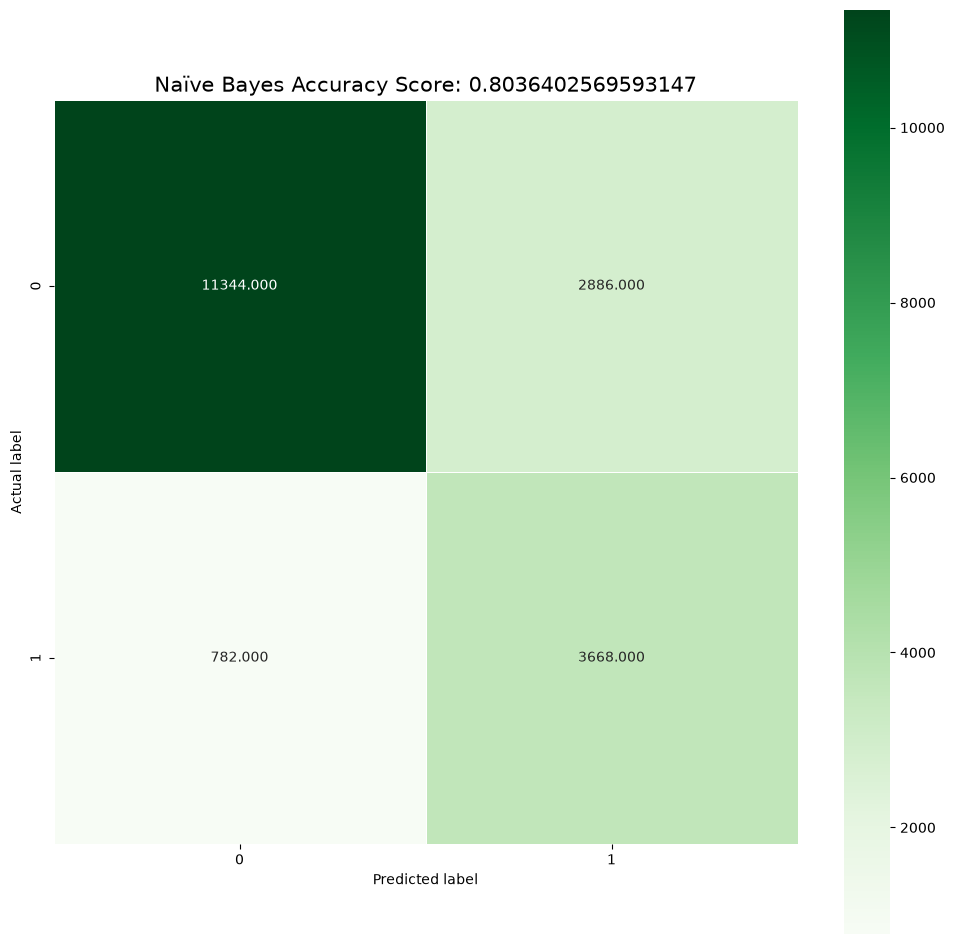

In [9]:
print("NguyenDucTinh - 6451071077")

# Xây dựng mô hình Naïve Bayes
gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)
bayes_score = metrics.accuracy_score(y_test, bayes_pred)

print("Accuracy (Naïve Bayes):", bayes_score)
print("Report:\n", metrics.classification_report(y_test, bayes_pred))

# Ma trận nhầm lẫn cho Naïve Bayes
bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)
plt.figure(figsize=(12, 12))
sns.heatmap(bayes_cm, annot=True, fmt=".3f", linewidths=.5, square=True, cmap='Greens')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Naïve Bayes Accuracy Score: {bayes_score}', size=15)
plt.show()